# Subscription Revenue Analysis

## Objective

The objective of this analysis is to understand subscription revenue distribution, compare revenue across subscription plans and billing frequencies, and investigate the relationship between subscription changes and recurring revenue.

## Business Questions

1. What is the total Monthly Recurring Revenue (MRR) across subscriptions?
2. What is the Annual Recurring Revenue (ARR) represented by the subscription records?
3. Which subscription plans contribute the most recurring revenue?
4. How does recurring revenue differ between monthly and annual billing?
5. How do upgrades and downgrades relate to subscription revenue?
6. How much revenue is associated with churned versus non-churned subscriptions?

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

subscriptions = pd.read_csv(
    "../data/raw/ravenstack_subscriptions.csv"
)

print("Dataset shape:", subscriptions.shape)

print("\nColumn names:")
print(subscriptions.columns.tolist())

display(subscriptions.head())

Dataset shape: (5000, 14)

Column names:
['subscription_id', 'account_id', 'start_date', 'end_date', 'plan_tier', 'seats', 'mrr_amount', 'arr_amount', 'is_trial', 'upgrade_flag', 'downgrade_flag', 'churn_flag', 'billing_frequency', 'auto_renew_flag']


,subscription_id,account_id,start_date,end_date,plan_tier,seats,mrr_amount,arr_amount,is_trial,upgrade_flag,downgrade_flag,churn_flag,billing_frequency,auto_renew_flag
0,S-8cec59,A-3c1a3f,2023-12-23,2024-04-12,Enterprise,14,2786,33432,False,False,False,True,monthly,True
1,S-0f6f44,A-9b9fe9,2024-06-11,NaN,Pro,17,833,9996,False,False,False,False,monthly,True
2,S-51c0d1,A-659280,2024-11-25,NaN,Enterprise,62,0,0,True,True,False,False,annual,False
3,S-f81687,A-e7a1e2,2024-11-23,2024-12-13,Enterprise,5,995,11940,False,False,False,True,monthly,True
4,S-cff5a2,A-ba6516,2024-01-10,NaN,Enterprise,27,5373,64476,False,False,False,False,monthly,True


1. What is the total Monthly Recurring Revenue (MRR) across subscriptions?

In [10]:
total_mrr=subscriptions['mrr_amount'].sum()
print(f"Total MRR across subscription records: ${total_mrr:,}")

Total MRR across subscription records: $11,338,747


2. What is the Annual Recurring Revenue (ARR) represented by the subscription records?

In [11]:
total_arr=subscriptions['arr_amount'].sum()
print(f"Total Arr Across subscription records: ${total_arr:,}")

Total Arr Across subscription records: $136,064,964


3. Which subscription plans contribute the most recurring revenue?

In [18]:
revenue_by_plan=(
    subscriptions
    .groupby("plan_tier")
    .agg(
        total_mrr=('mrr_amount','sum'),
        total_arr=('arr_amount','sum'),
        subscription_count=('subscription_id','count')
    )
    .reset_index()
)

revenue_by_plan['Shar of Total MRR']=(
    revenue_by_plan['total_mrr']/total_mrr*100
).round(2)

revenue_by_plan=revenue_by_plan.sort_values(
    by="total_mrr",
    ascending=False
)


display(revenue_by_plan)

,plan_tier,total_mrr,total_arr,subscription_count,Shar of Total MRR
1,Enterprise,8473221,101678652,1723,74.73
2,Pro,2105089,25261068,1675,18.57
0,Basic,760437,9125244,1602,6.71


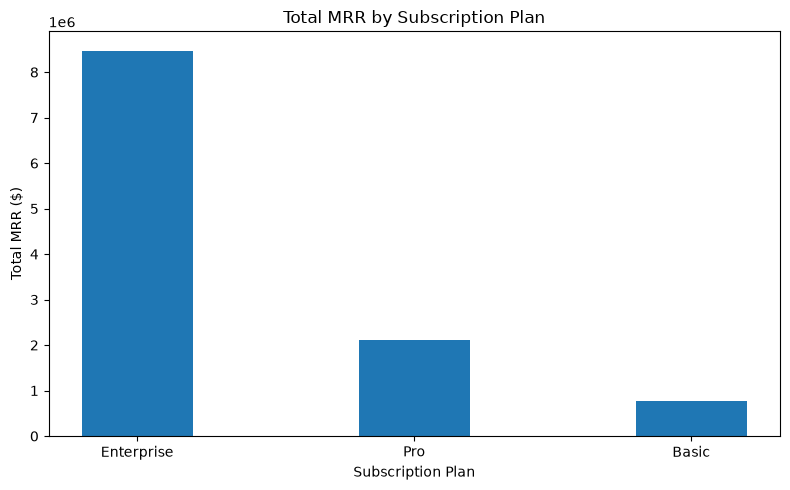

In [33]:
plt.figure(figsize=(8, 5))

plt.bar(
    revenue_by_plan["plan_tier"],
    revenue_by_plan["total_mrr"],
    width=0.4
)

plt.title("Total MRR by Subscription Plan")
plt.xlabel("Subscription Plan")
plt.ylabel("Total MRR ($)")

plt.tight_layout()
plt.show()

4. How does recurring revenue differ between monthly and annual billing?

In [ ]:
revenue_by_billing=(
    subscriptions
    .groupby('billing_frequency')
    .agg(
        total_mrr=('mrr_amount','sum'),
        total_arr=('arr_amount','sum'),
        subscription_count=('subscription_id','count')
    )
    .reset_index()  
)

revenue_by_billing=revenue_by_billing.sort_values(
    by="total_mrr",
    ascending=False     
)

revenue_by_billing['Shar of Total MRR']=(
    revenue_by_billing['total_mrr']/total_mrr*100
).round(2)
display(revenue_by_billing)

,billing_frequency,total_mrr,total_arr,subscription_count,Shar of Total MRR
1,monthly,5741349,68896188,2539,50.63
0,annual,5597398,67168776,2461,49.37


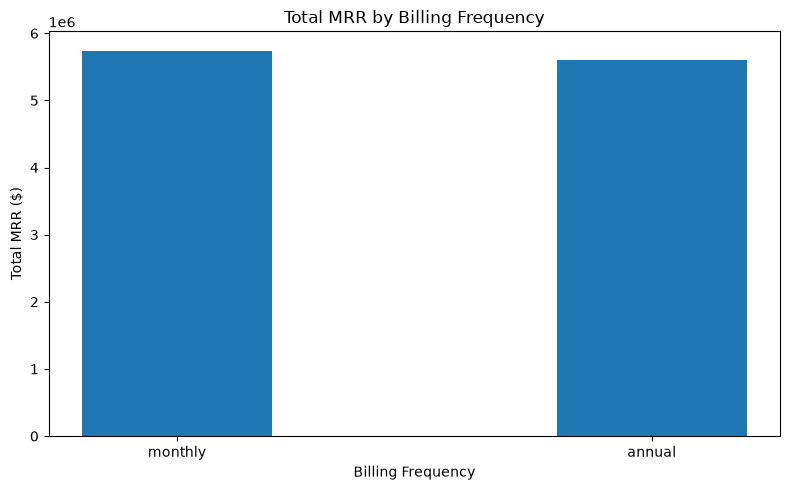

In [35]:
plt.figure(figsize=(8, 5))

plt.bar(
    revenue_by_billing["billing_frequency"],
    revenue_by_billing["total_mrr"],
    width=0.4
)

plt.title("Total MRR by Billing Frequency")
plt.xlabel("Billing Frequency")
plt.ylabel("Total MRR ($)")

plt.tight_layout()
plt.show()

5. How do upgrades and downgrades relate to subscription revenue?

In [ ]:
revenue_by_changes = subscriptions.groupby(
    ["upgrade_flag", "downgrade_flag"]
).agg(
    total_mrr=("mrr_amount", "sum"),
    total_arr=("arr_amount", "sum"),
    subscription_count=("subscription_id", "count")
).reset_index()

display(revenue_by_changes)

,upgrade_flag,downgrade_flag,total_mrr,total_arr,subscription_count
0,False,False,9656818,115881816,4276
1,False,True,418932,5027184,195
2,True,False,1222563,14670756,506
3,True,True,40434,485208,23


6. How much revenue is associated with churned versus non-churned subscriptions?

In [31]:
revenue_by_churn=(
    subscriptions
    .groupby("churn_flag")
    .agg(
        total_mrr=("mrr_amount", "sum"),
        total_arr=("arr_amount", "sum"),
        subscription_count=("subscription_id", "count"),
        average_mrr=("mrr_amount", "mean")
    )
)

revenue_by_churn['Shar of Total MRR']=(
    revenue_by_churn['total_mrr']/total_mrr*100
).round(2)
revenue_by_churn=revenue_by_churn.sort_values(
    by="total_mrr",
    ascending=False     
)
display(revenue_by_churn)


,total_mrr,total_arr,subscription_count,average_mrr,Shar of Total MRR
churn_flag,,,,,
False,10159608,121915296,4514,2250.688525,89.6
True,1179139,14149668,486,2426.211934,10.4


## Subscription Revenue Analysis Conclusion

The subscription revenue analysis examined recurring revenue across subscription plans, billing frequencies, subscription changes, and churn status.

The analysis found that Enterprise subscriptions contributed the largest share of total MRR, while monthly and annual billing contributed relatively similar amounts. Churned subscription records also had a higher average MRR than records not marked as churned.

These findings highlight the importance of understanding revenue concentration by plan and monitoring higher-value subscriptions for potential churn risk. Since the dataset includes historical subscription records, the aggregated revenue figures should not be interpreted as current revenue or confirmed revenue lost to churn.

See `docs/subscription_revenue_analysis_report.md` for the detailed findings and business recommendations.
